***Step 1*** : ***Load Dataset***



In [39]:
import pandas as pd

url = "https://raw.githubusercontent.com/SohelRaja/Customer-Churn-Analysis/master/Datasets/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset Loaded Successfully!")

print(df.head())

Dataset Loaded Successfully!
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV Streami

***Step 2*** : ***Data Cleaning***

In [40]:
# Check missing values

print("Missing Values:")
print(df.isnull().sum())

Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


***Convert TotalCharges into Numeric***

In [41]:
# Convert TotalCharges to numeric

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print(df["TotalCharges"].dtype)

float64


***Handle Missing Values***

In [42]:
# Fill missing values

df["TotalCharges"] = df["TotalCharges"].fillna(
    df["TotalCharges"].median()
)

print("Missing values handled successfully")

Missing values handled successfully


***Remove Customer ID***

In [43]:
# Remove unnecessary column

df.drop("customerID", axis=1, inplace=True)

print(df.head())

   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   
1    Male              0      No         No      34          Yes   
2    Male              0      No         No       2          Yes   
3    Male              0      No         No      45           No   
4  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          No          No              No  Month-to-month   
1              Yes          No  

***Step 3*** : ***Exploratory Data Analysis (EDA)***

3.1 Check Customer Churn

In [44]:
print(df["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


3.2 Visualize Customer Churn

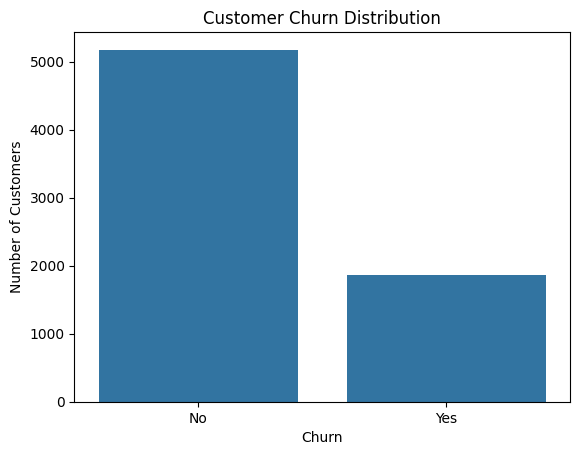

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")

plt.xlabel("Churn")

plt.ylabel("Number of Customers")

plt.show()

***STEP 4***: ***Customer Churn Analysis***

4.1 Analyze Churn by Contract Type

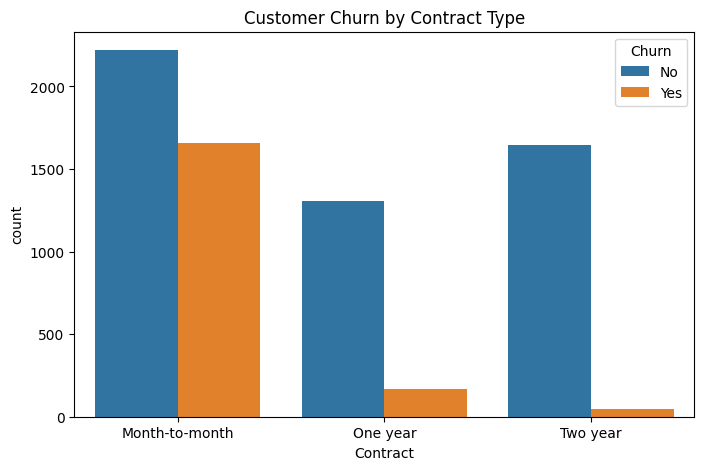

In [46]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")

plt.show()

4.2 Analyze Monthly Charges

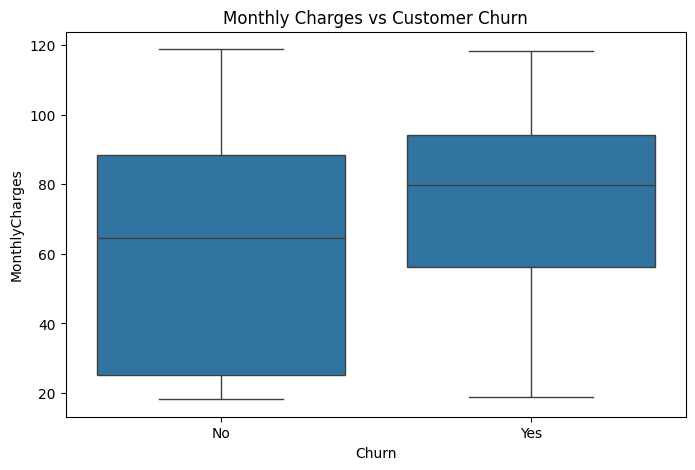

In [47]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Customer Churn")

plt.show()

***STEP 5*** : ***Prepare Data for Machine Learning***

In [48]:
from sklearn.preprocessing import LabelEncoder

# Convert categorical columns

for column in df.select_dtypes(include="object").columns:

    encoder = LabelEncoder()

    df[column] = encoder.fit_transform(df[column])

print(df.head())

   gender  SeniorCitizen  Partner  Dependents  tenure  PhoneService  \
0       0              0        1           0       1             0   
1       1              0        0           0      34             1   
2       1              0        0           0       2             1   
3       1              0        0           0      45             0   
4       0              0        0           0       2             1   

   MultipleLines  InternetService  OnlineSecurity  OnlineBackup  \
0              1                0               0             2   
1              0                0               2             0   
2              0                0               2             2   
3              1                0               2             0   
4              0                1               0             0   

   DeviceProtection  TechSupport  StreamingTV  StreamingMovies  Contract  \
0                 0            0            0                0         0   
1                 

***STEP 6***: ***Separate Features and Target***

In [49]:
# Features

X = df.drop("Churn", axis=1)

# Target

y = df["Churn"]

print("Features Shape:", X.shape)

print("Target Shape:", y.shape)

Features Shape: (7043, 19)
Target Shape: (7043,)


***STEP 7*** : ***Split Dataset***

In [50]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (5634, 19)
Testing Data: (1409, 19)


***STEP 8*** : ***Train Logistic Regression Mode***

In [51]:
from sklearn.linear_model import LogisticRegression

# Create Model
model = LogisticRegression(max_iter=1000)

# Train Model
model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


***STEP 9*** : ***Predict Customer Churn***

In [52]:
# Predict customer churn

y_pred = model.predict(X_test)

print("Customer Churn Prediction Completed!")


Customer Churn Prediction Completed!


***STEP 10*** : ***Check Model Accuracy***

In [53]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 79.91483321504613 %


***STEP 11*** : ***Classification Report***

In [54]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.64      0.55      0.59       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409



***STEP 12*** : ***Confusion Matrix***

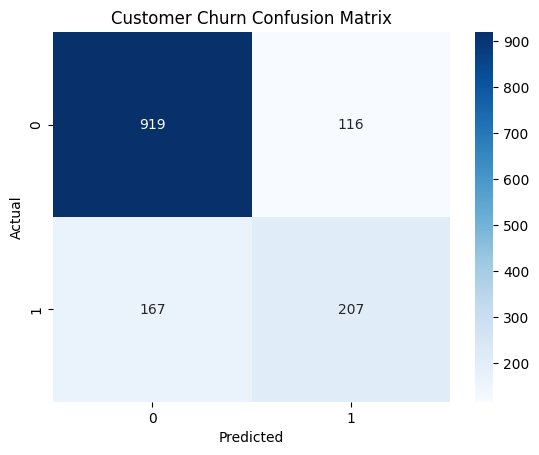

In [55]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Customer Churn Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

***STEP 13*** : ***Random Forest Model***

In [56]:
from sklearn.ensemble import RandomForestClassifier

# Create Model

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train Model

rf_model.fit(X_train, y_train)

# Predict

rf_pred = rf_model.predict(X_test)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


***STEP 14*** : ***Compare Model Accuracy***

In [57]:
from sklearn.metrics import accuracy_score

lr_accuracy = accuracy_score(y_test, y_pred)

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Logistic Regression Accuracy:", lr_accuracy * 100)

print("Random Forest Accuracy:", rf_accuracy * 100)

Logistic Regression Accuracy: 79.91483321504613
Random Forest Accuracy: 79.20511000709723


***STEP 15*** : ***Feature Importance Analysis***

15.1 : Calculate Feature Importance

In [58]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate feature importance
importance = rf_model.feature_importances_

# Create DataFrame
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

# Sort values
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

             Feature  Importance
18      TotalCharges    0.186841
17    MonthlyCharges    0.179192
4             tenure    0.154338
14          Contract    0.079631
16     PaymentMethod    0.050095
8     OnlineSecurity    0.049580
11       TechSupport    0.043603
0             gender    0.027892
7    InternetService    0.027789
9       OnlineBackup    0.027075
15  PaperlessBilling    0.025767
6      MultipleLines    0.023449
2            Partner    0.022726
10  DeviceProtection    0.021445
1      SeniorCitizen    0.021097
3         Dependents    0.019836
13   StreamingMovies    0.017632
12       StreamingTV    0.016804
5       PhoneService    0.005209


15.2 : Visualize Feature Importance

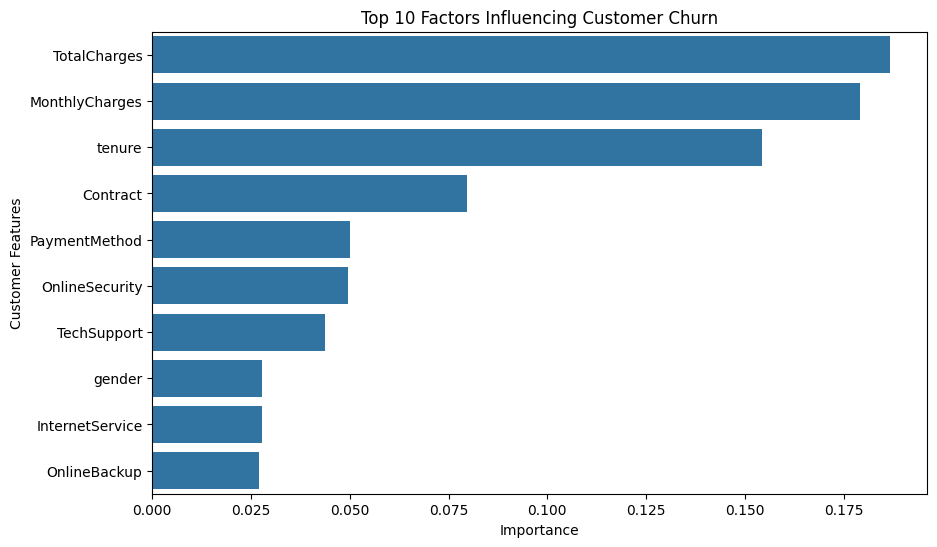

In [59]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Factors Influencing Customer Churn")

plt.xlabel("Importance")

plt.ylabel("Customer Features")

plt.show()

***STEP 16*** : ***Calculate  Customer Churn Percentage***

In [60]:
# Calculate total customers
total_customers = len(df)

# Calculate churned customers
churned_customers = (df["Churn"] == 1).sum()

# Calculate churn percentage
churn_percentage = (
    churned_customers / total_customers
) * 100

print("Total Customers:", total_customers)

print("Churned Customers:", churned_customers)

print("Customer Churn Percentage:", round(churn_percentage, 2), "%") :

Total Customers: 7043
Churned Customers: 1869
Customer Churn Percentage: 26.54 %


***STEP 17*** : ***Predict Churn for a Custome***

In [61]:
# Select one customer from test data

customer = X_test.iloc[[0]]

# Predict using Random Forest

prediction = rf_model.predict(customer)

# Display result

if prediction[0] == 1:
    print("Customer is likely to leave the company")
else:
    print("Customer is likely to stay with the company")

Customer is likely to stay with the company


***STEP 18*** : ***Business Insights***

In [62]:
# Calculate churn by contract type

contract_churn = df.groupby("Contract")["Churn"].mean() * 100

print("Customer Churn by Contract Type:")

print(contract_churn)

Customer Churn by Contract Type:
Contract
0    42.709677
1    11.269518
2     2.831858
Name: Churn, dtype: float64


***STEP 19*** : ***Final Business Insights***

In [63]:
# Calculate churn by contract type

contract_churn = df.groupby("Contract")["Churn"].mean() * 100

print("Customer Churn by Contract Type:")

print(contract_churn)

Customer Churn by Contract Type:
Contract
0    42.709677
1    11.269518
2     2.831858
Name: Churn, dtype: float64
